# Compare with Hiroshi's trajectories

*19 May 2025*

As a sanity check, want to compare trajectories computer by SeaIcBacktrack and those calculated for Sumata et al 2022.

Comparing one single trajectory by Hiroshi. Just a sanity check, not meant as a rigourous anything. The match shoudl be near 100%, if it is I will go ahead and trust that we can rely on the `SeaIceBackTrack` trajectories. 

*Note*: Did the comparison *almost correct* - an index error (`lat0, lon0=lat[1], lat[0]` instead of `lat0, lon0=lat[0], lat[0]`) made a small difference in the starting point.

**Verdict** is that these trajectories are basically identical and follow each other closely over years. 

**-> SeaIceBackTracj seems to do a good job!** More or less identical, the tiny difference is probably the initial starting point. Concluding that the exact interpolation method doesn't matter much.

Can probably say that we have compared with Hiroshi et al and they are identical to within X km after Y months. Or somethign to that effect. The island skipping stuff will need its own explanations though.

In [2]:
#Imports 
import pickle
import datetime

import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
from kval.maps import quickmap
from scipy.interpolate import interp1d

from matplotlib.ticker import MaxNLocator
%matplotlib widget

## Read Hiroshi's trajectory

In [3]:
# Location of the files
ddir_hiroshi = '../files_from_hiroshi/'

In [4]:
# Load HS's python script which defines his particle class
%run '../files_from_hiroshi/trajectory_util.py'

/home/oyvindf/work/code/python/SeaIceBacktrack/validation/trajectory_vs_sumata_new/files_from_hiroshi/trajectory_util.py:403: SyntaxWarning: invalid escape sequence '\ '
  sys.exit('ERROR: data does not exit, \    fname =' + fname)


#### Select one of the HS trajectories 

In [5]:
# Load one of the trajectory files
with open(f'{ddir_hiroshi}/FS.2018.01.backward_traj.731_days.n_8.pkl', 'rb') as f:
    trajectories = pickle.load(f) 

In [6]:
# Choose an index
traj_ind = 0

# Select the trajectory
traj_sel = trajectories[traj_ind]

# Extract lon/lat
lon_traj = np.array(traj_sel.lonlats)[:, 0]
lat_traj = np.array(traj_sel.lonlats)[:, 1]
time_traj = traj_sel.stamps

# Extract start date and coordinate
start_date_traj = time_traj[0]
lon0_traj = lon_traj[0]
lat0_traj = lat_traj[0]

## Backtrack using SeaIceBackTrack

In [7]:
# Ignore non-useful warnings
import warnings
warnings.simplefilter("ignore")

#### Run the notebooks for setting up the class and preparing the input data

In [8]:
print('Running other notebooks: Preparing data..\r', end = '')
%run "../../../particle_tracking/Load and prepare data.ipynb"
print('Running other notebooks: Defining particle tracking class..', end = '')
%run "../../../particle_tracking/Define particle tracking class.ipynb"
print('  ..done.')

<xarray.Dataset> Size: 3MBreparing data..
Dimensions:          (x: 240, y: 440)
Coordinates:
  * x                (x) float64 2kB -1.058e+05 -9.58e+04 ... 2.284e+06
  * y                (y) float64 4kB -1.706e+06 -1.696e+06 ... 2.684e+06
Data variables:
    lon              (y, x) float32 422kB ...
    lat              (y, x) float32 422kB ...
    landmask         (y, x) float64 845kB ...
    landmask_wo_svb  (y, x) float64 845kB ...
Attributes:
    Conventions:  COARDS, CF-1.5
    title:        Produced by grdconvert
    history:      grdconvert cut/ibcao-v4.2-400m.tiff cut/ibcao-v4.2-400m.nc
    description:  
    GMT_version:  5.4.5 [64-bit]
    node_offset:  1
Running other notebooks: Defining particle tracking class..  ..done.


##### Choose whether to compute or load from previously saved file

In [9]:
compute_traj = True # Either load or recompute (takes 30-60 minutes)

##### *If selected*: Load from file

In [10]:
if not compute_traj:
    with open('trajectory_saved.p', 'wb') as f:
        pickle.dump(P, f)

##### *Otherwise*: Compute trajectories 

Note: Trajectory goes through the TPD and into the Beaufort gyre over >3 years and therefore takes a while time to compute - *after recent improvements, only 4m30s*.

In [11]:
%%time 
if compute_traj:

    inputs = IceParticleInputs(ds)
    
    IC_dict = {'inputs':inputs, 
          'lat0':lat0_traj, 
          'lon0':lon0_traj, 
          'time0':start_date_traj, 
          'MASK':MASK, 'interp_method':'linear', 
               'end_criteria':'ABC',}
    
    # Set up object, compute the trajectory, and save to TRAJS
    P = IceParticle(IC_dict)
    P.backtrack()

 ..done.
HIT OPEN WATER! () step 1214 (19 Sep 2014) - 2715.8 km ..
CPU times: user 5min 13s, sys: 26.7 s, total: 5min 40s
Wall time: 4min 21s


In [ ]:
P.MASK

### Plot the trajectories together

Note: If loaded from the file there may have been a (small) error in start latitude. (Fixed in the code above but didn't bother to rerun the trajectory)

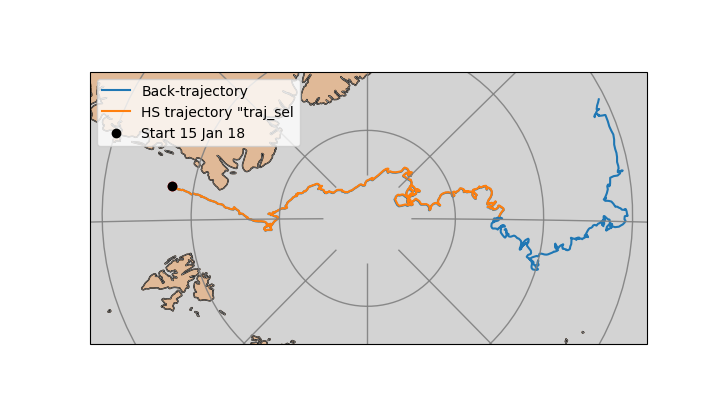

In [15]:
plt.close('all')

crs = ccrs.Stereographic(central_latitude=80.0, central_longitude=90.0, false_easting=0.0, 
                          false_northing=0.0, true_scale_latitude=None, globe=None)
fig = plt.figure(figsize = [7.19, 4.14])
ax = fig.add_subplot(111, projection=crs)

ax.coastlines()
ax.add_feature(cfeature.LAND, color = 'tab:orange', alpha = 0.3)
ax.add_feature(cfeature.COASTLINE, color = 'gray', lw = 0.5)
ax.set_extent([-45, 125, 60, 60])

ax.set_xlim(-1776630, 1790654)
ax.set_ylim(315596, 2059603)
ax.set_facecolor('lightgray')

ax.plot(lon0_traj, lat0_traj, 'or',transform = ccrs.PlateCarree(), )


Plat, Plon = P.lat, P.lon #P.ease2_to_latlon.transform(P.x, P.y)

# Massage to make lon continuous
Plon[Plon<100] +=360

datestr = num2date(date2num(P.time0)).strftime('%d %b %y')

ax.plot(Plon, Plat, transform = ccrs.PlateCarree(), label = 'Back-trajectory')
ax.plot(lon_traj, lat_traj, transform = ccrs.PlateCarree(), label = 'HS trajectory "traj_sel')
ax.plot(Plon[0], Plat[0], 'ok', transform = ccrs.PlateCarree(), label = 'Start %s'%datestr)

gls = ax.gridlines(draw_labels=False, crs=ccrs.PlateCarree(), lw=1, color="gray",
        y_inline=True, xlocs=range(-180,180,45), ylocs=range(0,90,5), alpha = 0.9,  ylim=87.5, )
ax.legend()

In [16]:
P.end_reason

'(A) Particle hit open water (nearest non-landmasked point has u = v = NaN (<15%SIC))'

## PLot lon/lat on time together

In [17]:
Pdate = num2date(P.time_num)

In [20]:
Plat_ip = interp1d(P.time_num, Plat)(date2num(traj_sel.stamps))
Plon_ip = interp1d(P.time_num, Plon)(date2num(traj_sel.stamps))

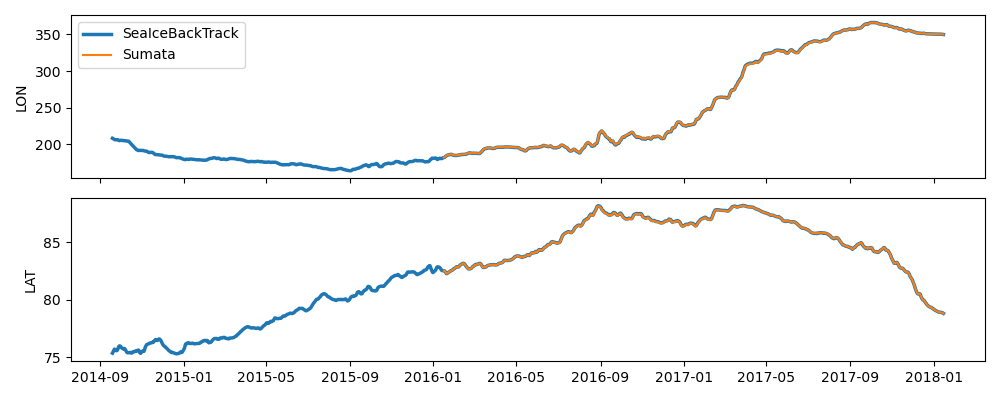

In [48]:
fig, ax = plt.subplots(2, 1, sharex = True, figsize = (10, 4))
ax[0].plot(Pdate, Plon, lw = 2.5, label = 'SeaIceBackTrack')
ax[0].plot(traj_sel.stamps, lon_traj+360, label = 'Sumata')
ax[1].plot(Pdate, Plat, lw = 2.5, label = 'SeaIceBackTrack' )
ax[1].plot(traj_sel.stamps, lat_traj, label = 'Sumata')
#ax[1].plot(traj_sel.stamps, Plat_ip)
ax[0].legend()
ax[0].set_ylabel('LON')
ax[1].set_ylabel('LAT')

plt.tight_layout()


In [22]:
from kval.geo import geocalc 

In [32]:
x_km_diff = np.array([geocalc.great_circle_distance(tlon, tlat, plon, plat) 
                      for tlon, tlat, plon, plat in zip(lon_traj, lat_traj, Plon_ip, Plat_ip)])*1e-3

In [58]:
P.

np.float64(2715834.085792013)

In [64]:
x_km_total_sumata = np.array([geocalc.great_circle_distance(tlon, tlat,  lon_traj[0], lat_traj[0]) 
                       for tlon, tlat in zip(lon_traj, lat_traj,)])*1e-3

In [65]:
x_km_total_sib = np.array([geocalc.great_circle_distance(tlon, tlat,  lon_traj[0], lat_traj[0]) 
                       for tlon, tlat in zip(Plon, Plat,)])*1e-3

In [66]:
x_km_total_sib

array([   0.        ,    6.11624893,   10.57158267, ..., 2705.27311514,
       2715.14532414, 2722.442243  ], shape=(1215,))

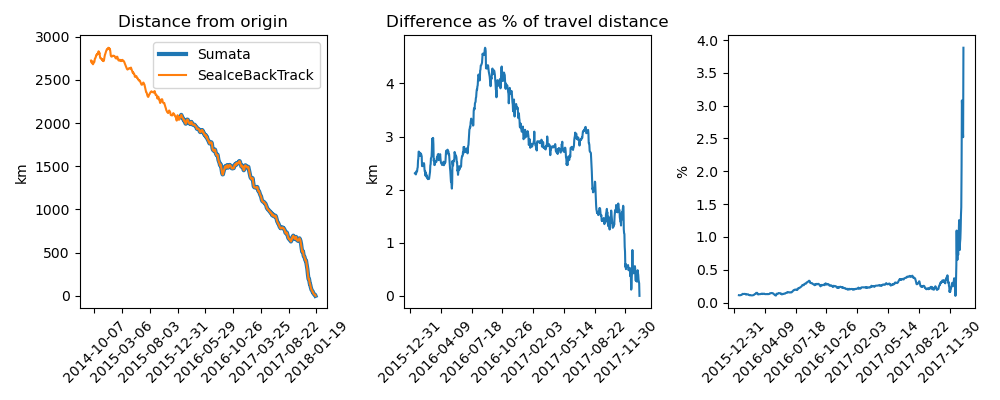

In [73]:
fig, ax = plt.subplots(1, 3, figsize = (10, 4))
ax[0].plot(traj_sel.stamps, x_km_total_sumata, label = 'Sumata', lw = 3)
ax[0].plot(Pdate, x_km_total_sib, label = 'SeaIceBackTrack' )


ax[1].plot(traj_sel.stamps, x_km_diff)
ax[2].plot(traj_sel.stamps, x_km_diff/x_km_total*100)
ax[0].set_title('Distance from origin')
ax[0].set_ylabel('km')
ax[1].set_title('Distance between trajectories')
ax[1].set_title('Difference as % of travel distance')
ax[1].set_ylabel('km')

ax[2].set_ylabel('%')
ax[0].legend()

# Reduce x-tick density
for a in ax:
    # Set x-ticks to show every nth tick (e.g., every 5th tick)
    a.xaxis.set_major_locator(MaxNLocator(10))  # Show at most 10 ticks
    a.tick_params(axis='x', rotation=45)

plt.tight_layout()
